# 01 · EDA — Churn Bancario

Análisis exploratorio del dataset `competencia_01.csv`.  
Objetivo: entender estructura, distribuciones, missings y dinámica temporal del churn **sin cargar más datos de los necesarios en RAM**.

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 1 — Exploración  
**Última actualización:** 2026-10

## 0 · Setup y montaje de Drive

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

RUTA_CARPETA = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
ARCHIVO_DATOS = RUTA_CARPETA / 'competencia_01.csv'

print(f'Ruta verificada: {ARCHIVO_DATOS.exists()}')

Ruta verificada: True


## 1 · Inspección inicial sin cargar todo el dataset

Leemos sólo las primeras filas para ver columnas y tipos **antes** de decidir cómo cargar el archivo completo.

In [9]:
# Muestra mínima: sólo para inspeccionar cabecera y tipos
muestra = pd.read_csv(ARCHIVO_DATOS, nrows=500)

print(f'Filas en muestra: {len(muestra):,}')
print(f'Columnas: {muestra.shape[1]}')
print(f'\nColumnas disponibles:')
print(muestra.columns.tolist())

Filas en muestra: 500
Columnas: 155

Columnas disponibles:
['numero_de_cliente', 'foto_mes', 'active_quarter', 'cliente_vip', 'internet', 'cliente_edad', 'cliente_antiguedad', 'mrentabilidad', 'mrentabilidad_annual', 'mcomisiones', 'mactivos_margen', 'mpasivos_margen', 'cproductos', 'tcuentas', 'ccuenta_corriente', 'mcuenta_corriente_adicional', 'mcuenta_corriente', 'ccaja_ahorro', 'mcaja_ahorro', 'mcaja_ahorro_adicional', 'mcaja_ahorro_dolares', 'cdescubierto_preacordado', 'mcuentas_saldo', 'ctarjeta_debito', 'ctarjeta_debito_transacciones', 'mautoservicio', 'ctarjeta_visa', 'ctarjeta_visa_transacciones', 'mtarjeta_visa_consumo', 'ctarjeta_master', 'ctarjeta_master_transacciones', 'mtarjeta_master_consumo', 'cprestamos_personales', 'mprestamos_personales', 'cprestamos_prendarios', 'mprestamos_prendarios', 'cprestamos_hipotecarios', 'mprestamos_hipotecarios', 'cplazo_fijo', 'mplazo_fijo_dolares', 'mplazo_fijo_pesos', 'cinversion1', 'minversion1_pesos', 'minversion1_dolares', 'cinversio

In [10]:
# Tipos inferidos y memoria estimada antes de optimizar
print('Tipos inferidos por pandas:')
print(muestra.dtypes.value_counts())
print(f'\nMemoria muestra (500 filas): {muestra.memory_usage(deep=True).sum() / 1024:.1f} KB')

# Extrapolación de memoria si cargamos todo sin optimizar
total_filas_aprox = sum(1 for _ in open(ARCHIVO_DATOS)) - 1  # descuenta header
factor = total_filas_aprox / len(muestra)
mem_estimada_mb = muestra.memory_usage(deep=True).sum() * factor / 1024**2
print(f'\nFilas totales en el archivo: {total_filas_aprox:,}')
print(f'Memoria estimada sin optimizar: {mem_estimada_mb:.0f} MB')

Tipos inferidos por pandas:
float64    89
int64      65
object      1
Name: count, dtype: int64

Memoria muestra (500 filas): 629.8 KB

Filas totales en el archivo: 983,061
Memoria estimada sin optimizar: 1209 MB


In [11]:
muestra.head(3)

,numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,...,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria
0,12202151,202103,1,0,0,53,375,5559.50,26357.31,2180.24,...,7.0,0.00,-83798.88,0.0,7520.0,78807.51,12.0,0.0,8093.70,continua
1,12202151,202104,1,0,0,53,376,4540.15,30165.43,2305.64,...,9.0,0.00,-123331.51,0.0,7550.0,76183.06,10.0,0.0,8598.09,continua
2,12202151,202105,1,0,0,53,377,7392.72,33894.55,2091.64,...,12.0,10134.72,-113717.92,0.0,7581.0,42283.92,15.0,0.0,10134.72,continua


## 2 · Carga optimizada

Construimos un diccionario de `dtype` a partir de la muestra para **reducir la huella de RAM al cargar el dataset completo**.  
Reglas aplicadas:
- `float64` → `float32`  
- `int64` → el entero más chico que aguante el rango  
- `object` con pocos valores únicos → `category`

In [12]:
def inferir_dtypes_optimos(df_muestra: pd.DataFrame, umbral_categorica: float = 0.05) -> dict:
    """
    Devuelve un diccionario col -> dtype optimizado basado en una muestra.
    - float64 -> float32
    - int64   -> int más chico posible
    - object con cardinalidad baja -> category
    """
    dtypes = {}
    for col in df_muestra.columns:
        tipo = df_muestra[col].dtype
        if tipo == 'float64':
            dtypes[col] = 'float32'
        elif tipo == 'int64':
            col_min = df_muestra[col].min()
            col_max = df_muestra[col].max()
            if col_min >= 0:
                if col_max < 256:       dtypes[col] = 'uint8'
                elif col_max < 65536:   dtypes[col] = 'uint16'
                else:                   dtypes[col] = 'uint32'
            else:
                if col_min > -128 and col_max < 128:     dtypes[col] = 'int8'
                elif col_min > -32768 and col_max < 32768: dtypes[col] = 'int16'
                else:                                      dtypes[col] = 'int32'
        elif tipo == 'object':
            ratio = df_muestra[col].nunique() / len(df_muestra)
            if ratio < umbral_categorica:
                dtypes[col] = 'category'
    return dtypes


dtypes_optimos = inferir_dtypes_optimos(muestra)
print(f'Columnas con dtype optimizado: {len(dtypes_optimos)} / {muestra.shape[1]}')
print(dtypes_optimos)

Columnas con dtype optimizado: 155 / 155
{'numero_de_cliente': 'uint32', 'foto_mes': 'uint32', 'active_quarter': 'uint8', 'cliente_vip': 'uint8', 'internet': 'uint8', 'cliente_edad': 'uint8', 'cliente_antiguedad': 'uint16', 'mrentabilidad': 'float32', 'mrentabilidad_annual': 'float32', 'mcomisiones': 'float32', 'mactivos_margen': 'float32', 'mpasivos_margen': 'float32', 'cproductos': 'uint8', 'tcuentas': 'uint8', 'ccuenta_corriente': 'uint8', 'mcuenta_corriente_adicional': 'float32', 'mcuenta_corriente': 'float32', 'ccaja_ahorro': 'uint8', 'mcaja_ahorro': 'float32', 'mcaja_ahorro_adicional': 'float32', 'mcaja_ahorro_dolares': 'float32', 'cdescubierto_preacordado': 'uint8', 'mcuentas_saldo': 'float32', 'ctarjeta_debito': 'uint8', 'ctarjeta_debito_transacciones': 'uint8', 'mautoservicio': 'float32', 'ctarjeta_visa': 'uint8', 'ctarjeta_visa_transacciones': 'uint8', 'mtarjeta_visa_consumo': 'float32', 'ctarjeta_master': 'uint8', 'ctarjeta_master_transacciones': 'uint8', 'mtarjeta_master_co

In [13]:
# Liberamos la muestra antes de cargar el dataset completo
del muestra
gc.collect()

# Carga completa con dtypes optimizados
df = pd.read_csv(ARCHIVO_DATOS, dtype=dtypes_optimos, low_memory=False)

mem_real_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f'Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Memoria real en RAM: {mem_real_mb:.1f} MB')

Dataset cargado: 983,061 filas × 155 columnas
Memoria real en RAM: 404.1 MB


## 3 · Estructura general

In [14]:
# Vista rápida de tipos y primeras filas
df.dtypes.to_frame('dtype').assign(
    nunique=df.nunique(),
    pct_nulos=df.isna().mean().mul(100).round(2)
).sort_values('pct_nulos', ascending=False)

,dtype,nunique,pct_nulos
Master_Finiciomora,float32,127,99.51
Visa_Finiciomora,float32,142,98.64
Master_mpagospesos,float32,252625,58.95
Master_mconsumosdolares,float32,7152,58.95
Master_cconsumos,float32,110,58.95
...,...,...,...
ccajas_otras,uint8,42,0.00
catm_trx,uint8,104,0.00
matm,float32,5703,0.00
catm_trx_other,uint8,52,0.00


In [15]:
df.head(3)

,numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,...,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria
0,12202151,202103,1,0,0,53,375,5559.500000,26357.310547,2180.239990,...,7.0,0.000000,-83798.882812,0.0,7520.0,78807.507812,12.0,0.0,8093.700195,continua
1,12202151,202104,1,0,0,53,376,4540.149902,30165.429688,2305.639893,...,9.0,0.000000,-123331.507812,0.0,7550.0,76183.062500,10.0,0.0,8598.089844,continua
2,12202151,202105,1,0,0,53,377,7392.720215,33894.550781,2091.639893,...,12.0,10134.719727,-113717.921875,0.0,7581.0,42283.921875,15.0,0.0,10134.719727,continua


## 4 · Variable target: `clase_ternaria`

Identificamos qué valores toma la variable objetivo y cómo se distribuye.

                     n      %
clase_ternaria               
continua        645999  65.71
sin_target      328995  33.47
baja2             4067   0.41
baja1             4000   0.41


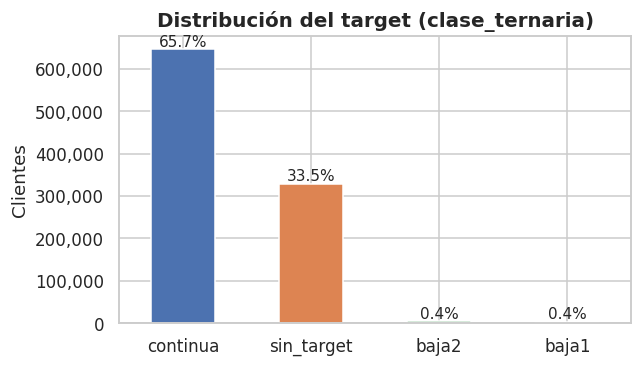

In [16]:
# Asumimos que la columna target se llama 'clase_ternaria'.
# Si el nombre difiere en el CSV, ajustar aquí.
TARGET = 'clase_ternaria'

if TARGET not in df.columns:
    print(f'⚠️  Columna "{TARGET}" no encontrada. Columnas disponibles:')
    print(df.columns.tolist())
else:
    conteo = df[TARGET].value_counts(dropna=False)
    pct    = df[TARGET].value_counts(normalize=True, dropna=False).mul(100).round(2)
    resumen_target = pd.DataFrame({'n': conteo, '%': pct})
    print(resumen_target)

    # Gráfico
    fig, ax = plt.subplots(figsize=(6, 3.5))
    conteo.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='white')
    ax.set_title('Distribución del target (clase_ternaria)', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Clientes')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    for p in ax.patches:
        ax.annotate(f'{p.get_height()/len(df)*100:.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 5 · Dimensión temporal

Verificamos qué columna identifica el mes/período y cuántos períodos hay.

In [17]:
# Columna de período — ajustar si el nombre difiere
COL_PERIODO = 'foto_mes'   # valor típico en competencias de este tipo

if COL_PERIODO not in df.columns:
    print(f'⚠️  Columna "{COL_PERIODO}" no encontrada. Columnas disponibles:')
    print(df.columns.tolist())
else:
    periodos = df[COL_PERIODO].value_counts().sort_index()
    print(f'Períodos disponibles: {periodos.index.min()} → {periodos.index.max()}')
    print(f'Total de meses: {len(periodos)}')
    print('\nFilas por mes:')
    print(periodos.to_string())

Períodos disponibles: 202103 → 202108
Total de meses: 6

Filas por mes:
foto_mes
202103    162900
202104    163284
202105    163768
202106    164114
202107    164348
202108    164647


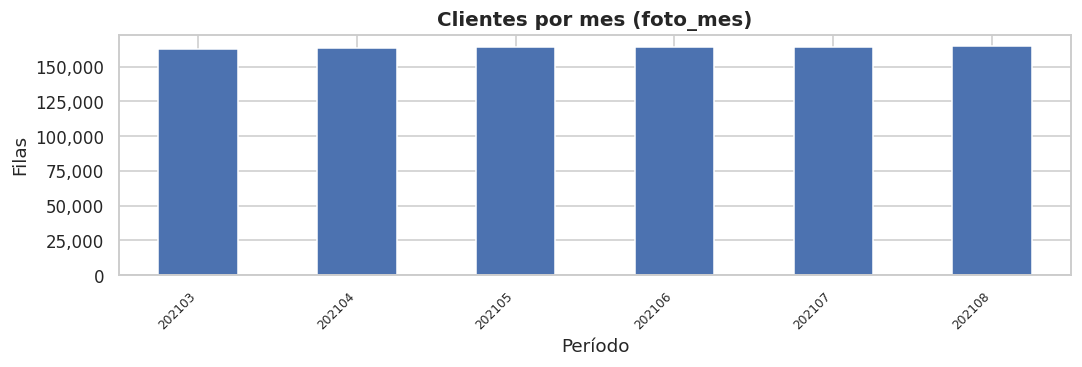

In [18]:
if COL_PERIODO in df.columns:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    periodos.plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='white')
    ax.set_title('Clientes por mes (foto_mes)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Período')
    ax.set_ylabel('Filas')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.tight_layout()
    plt.show()

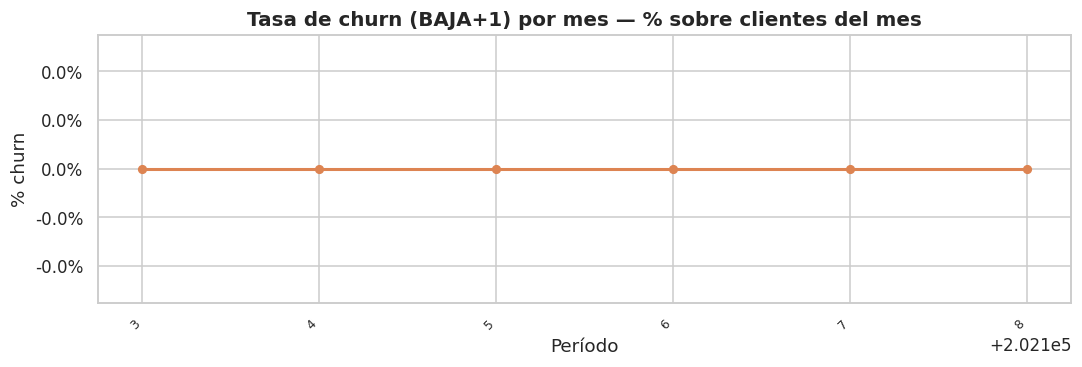


Estadísticas de tasa de churn mensual:
count    6.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: tasa_churn_pct, dtype: float64


In [19]:
# Tasa de churn (BAJA+1) por mes
if COL_PERIODO in df.columns and TARGET in df.columns:
    churn_label = 'BAJA+1'   # ajustar si el label difiere

    tasa_churn = (
        df.groupby(COL_PERIODO)[TARGET]
        .apply(lambda s: (s == churn_label).sum() / len(s) * 100)
        .rename('tasa_churn_pct')
    )

    fig, ax = plt.subplots(figsize=(10, 3.5))
    tasa_churn.plot(ax=ax, marker='o', color='#DD8452', linewidth=2, markersize=5)
    ax.set_title('Tasa de churn (BAJA+1) por mes — % sobre clientes del mes', fontsize=13, fontweight='bold')
    ax.set_xlabel('Período')
    ax.set_ylabel('% churn')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.tight_layout()
    plt.show()

    print('\nEstadísticas de tasa de churn mensual:')
    print(tasa_churn.describe().round(2))

## 6 · Missings

Mapa de columnas con valores faltantes — sólo mostramos las que tienen al menos 1% de nulos.

Columnas con ≥ 1% de nulos: 46 / 155


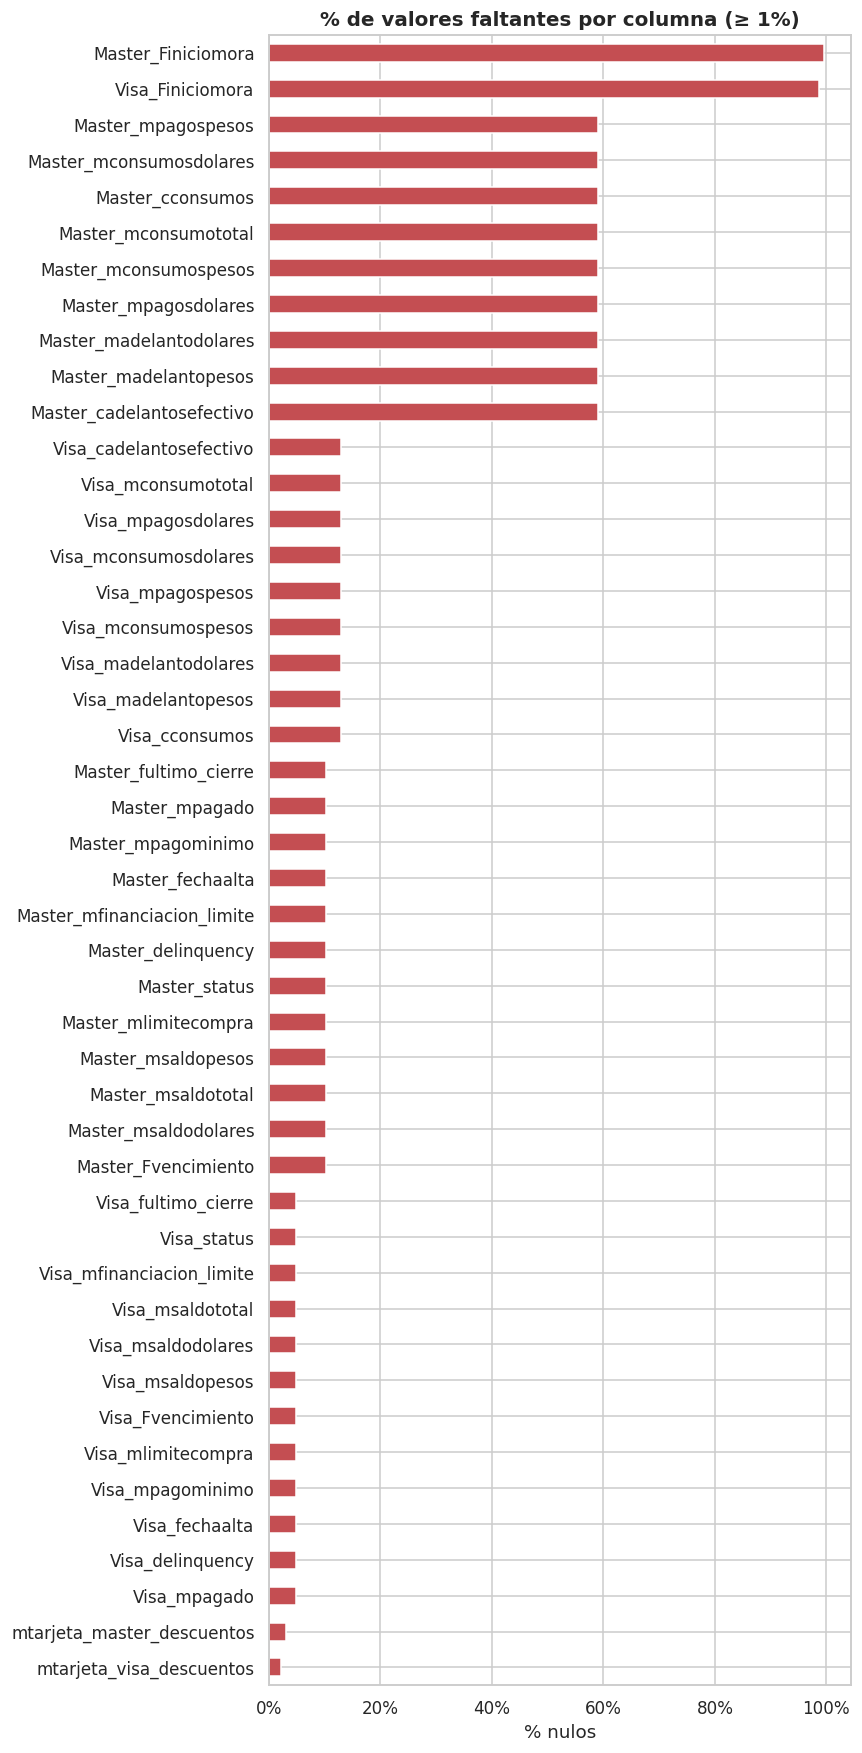

In [20]:
pct_nulos = df.isna().mean().mul(100).sort_values(ascending=False)
nulos_relevantes = pct_nulos[pct_nulos >= 1]

print(f'Columnas con ≥ 1% de nulos: {len(nulos_relevantes)} / {df.shape[1]}')

if len(nulos_relevantes) > 0:
    fig, ax = plt.subplots(figsize=(8, max(3, len(nulos_relevantes) * 0.35)))
    nulos_relevantes.plot(kind='barh', ax=ax, color='#C44E52', edgecolor='white')
    ax.set_title('% de valores faltantes por columna (≥ 1%)', fontsize=13, fontweight='bold')
    ax.set_xlabel('% nulos')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print('✓ Sin columnas con nulos significativos.')

## 7 · Distribución de variables numéricas

Estadísticas descriptivas del último mes disponible para no mezclar períodos.

In [21]:
if COL_PERIODO in df.columns:
    ultimo_mes = df[COL_PERIODO].max()
    df_ultimo = df[df[COL_PERIODO] == ultimo_mes].copy()
    print(f'Analizando el mes más reciente: {ultimo_mes} ({len(df_ultimo):,} clientes)')
else:
    df_ultimo = df.copy()
    print('Sin columna de período — usando dataset completo')

Analizando el mes más reciente: 202108 (164,647 clientes)


In [22]:
# Estadísticas descriptivas — sólo numéricas
desc = df_ultimo.select_dtypes(include=[np.number]).describe().T
desc['cv'] = (desc['std'] / desc['mean']).round(3)   # coeficiente de variación
desc = desc.sort_values('cv', ascending=False)
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,cv
mcuenta_corriente_adicional,164647.0,58.192,7972.079,-67486.047,0.000,0.000,0.00,2.031896e+06,136.997
Master_madelantodolares,68652.0,0.009,1.149,0.000,0.000,0.000,0.00,1.686000e+02,131.351
mpagodeservicios,164647.0,265.518,34195.863,0.000,0.000,0.000,0.00,1.354154e+07,128.789
Visa_madelantodolares,143677.0,0.012,1.299,0.000,0.000,0.000,0.00,1.776300e+02,107.537
minversion1_dolares,164647.0,4079.074,342486.250,0.000,0.000,0.000,0.00,1.227908e+08,83.962
...,...,...,...,...,...,...,...,...,...
Visa_mpagospesos,143677.0,-42972.855,60899.402,-2629773.750,-52196.352,-26233.131,-11730.00,1.572736e+05,-1.417
Master_mpagospesos,68652.0,-19731.082,46643.492,-2638276.500,-21222.771,-8339.635,-2678.73,9.732809e+04,-2.364
mactivos_margen,164647.0,-976.421,4655.367,-209195.203,-1816.700,-550.270,4.31,2.371289e+05,-4.768
Master_Fvencimiento,147943.0,-1016.252,7600.231,-2914025.000,-1429.000,-942.000,-425.00,7.003000e+03,-7.479


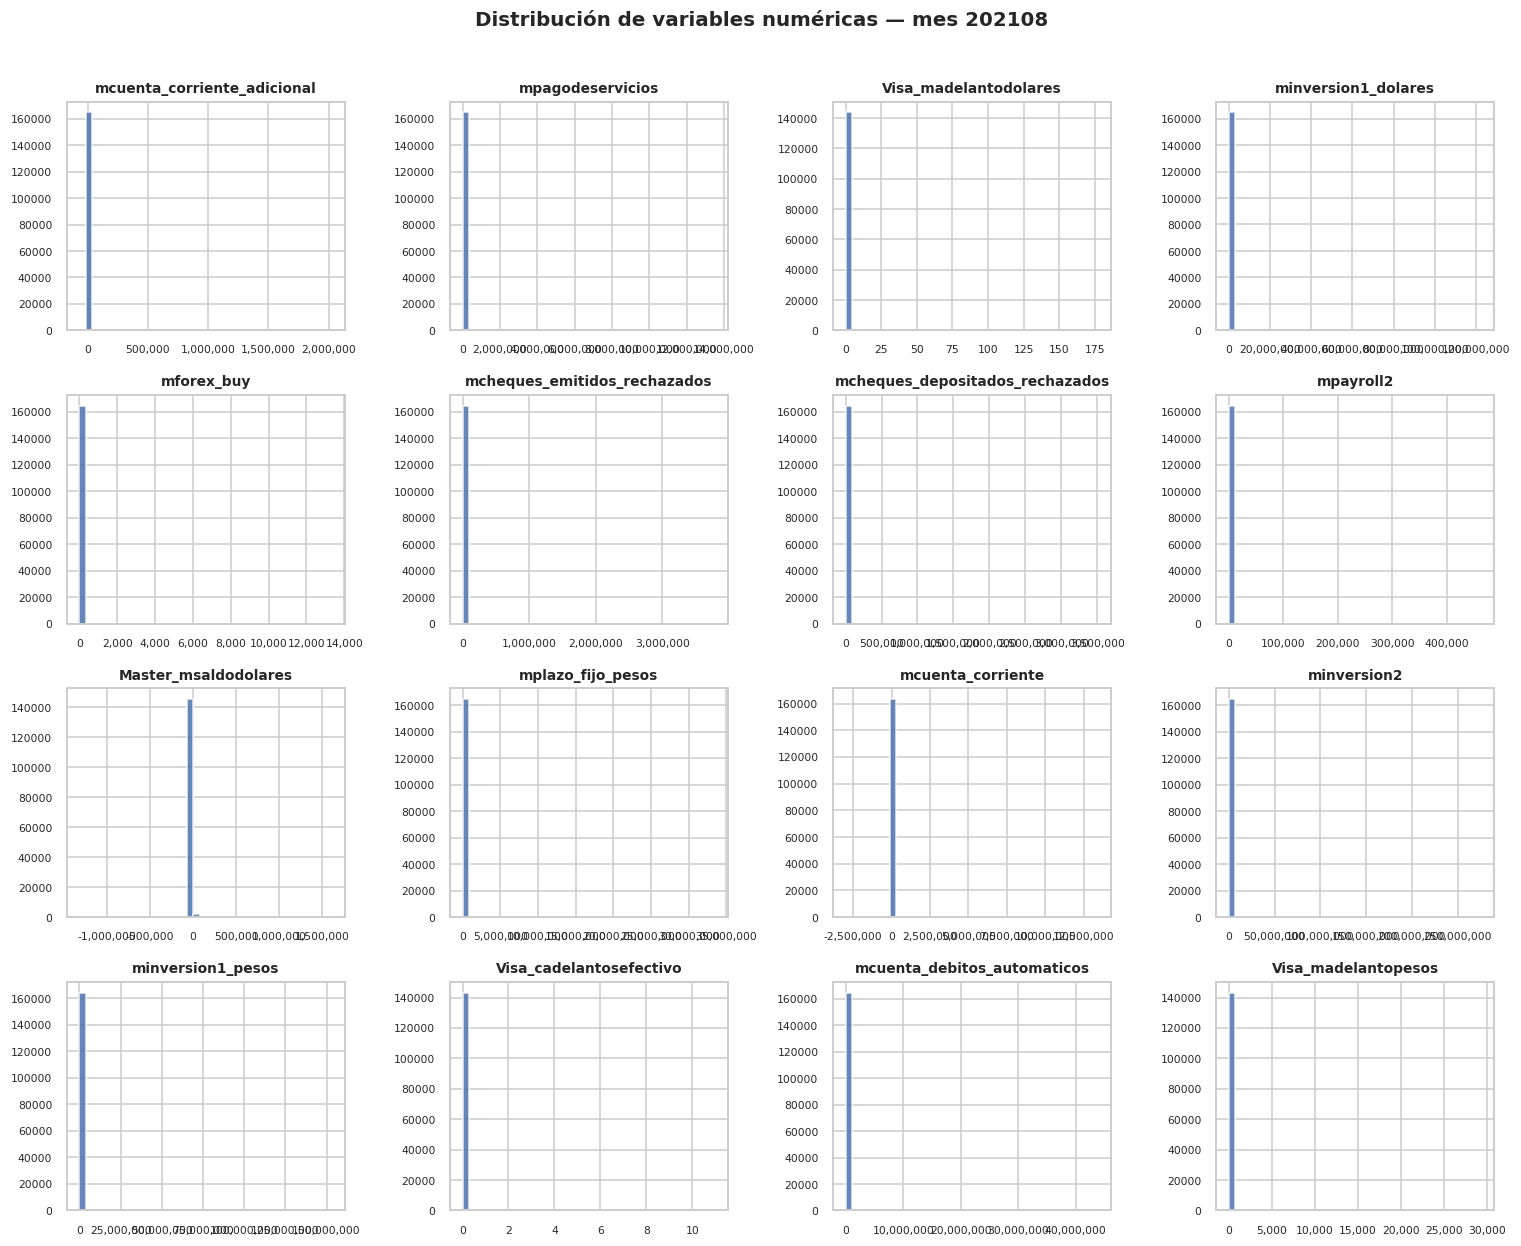

24

In [23]:
# Histogramas de las top-N columnas numéricas con mayor variabilidad relativa
# Excluimos IDs y la columna de período
EXCLUIR = {COL_PERIODO, 'numero_de_cliente', 'id', 'ID'}  # ajustar según el dataset
cols_num = [
    c for c in desc.index
    if c not in EXCLUIR and df_ultimo[c].nunique() > 10
][:16]  # máximo 16 para no saturar RAM con gráficos

n_cols = 4
n_rows = -(-len(cols_num) // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 2.8))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    data = df_ultimo[col].dropna()
    axes[i].hist(data, bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].tick_params(labelsize=7)
    axes[i].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f'Distribución de variables numéricas — mes {ultimo_mes}', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Liberamos el subconjunto
del df_ultimo
gc.collect()

## 8 · Correlación con el target

Calculamos correlación de punto biserial entre cada variable numérica y un indicador binario de churn.  
Mostramos las top 20 más correlacionadas (positiva o negativamente).

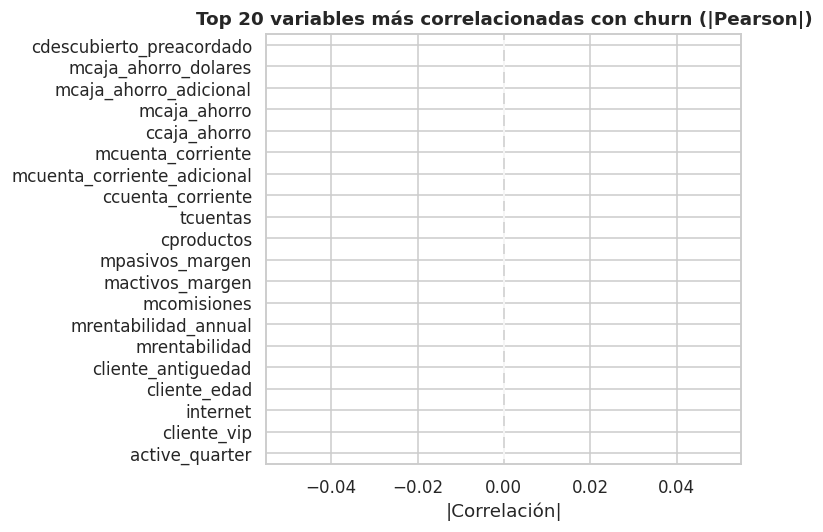

In [24]:
if TARGET in df.columns:
    # Tomamos sólo los meses donde hay target real (no el último si no tiene label)
    df_con_target = df[df[TARGET].notna()].copy()

    # Codificamos el target como binario: 1 = BAJA+1
    df_con_target['_churn'] = (df_con_target[TARGET] == 'BAJA+1').astype('int8')

    numericas = df_con_target.select_dtypes(include=[np.number]).columns.tolist()
    numericas = [c for c in numericas if c not in EXCLUIR | {COL_PERIODO, '_churn'}]

    # Correlación de Pearson como proxy (eficiente en RAM)
    corr = (
        df_con_target[numericas + ['_churn']]
        .corr()['_churn']
        .drop('_churn')
        .abs()
        .sort_values(ascending=False)
        .head(20)
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    corr.sort_values().plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='white')
    ax.set_title('Top 20 variables más correlacionadas con churn (|Pearson|)', fontsize=12, fontweight='bold')
    ax.set_xlabel('|Correlación|')
    plt.tight_layout()
    plt.show()

    del df_con_target
    gc.collect()
else:
    print(f'⚠️  Columna target "{TARGET}" no encontrada — omitimos análisis de correlación.')

## 9 · Resumen ejecutivo

Celda de texto para completar con los hallazgos principales una vez corrida la notebook.

### Hallazgos principales

*(Completar tras correr la notebook)*

| Dimensión | Observación |
|---|---|
| Tamaño del dataset | — |
| Rango temporal | — |
| Tasa de churn promedio | — |
| Variables con nulos críticos | — |
| Variables más correlacionadas con churn | — |
| Notas de calidad / anomalías | — |

In [25]:
# Limpieza final de RAM
del df
gc.collect()
print('✓ Memoria liberada. EDA completado.')

✓ Memoria liberada. EDA completado.
